# Algoritmos genéticos y computación evolutiva

**Bloque 03 · Métodos poblacionales · Notebook 09**

Navegación: [← 08 Colonia de hormigas](../02-metodos-con-memoria/08-colonia-de-hormigas.ipynb) · [10 BRKGA, meméticos y scatter search →](10-brkga-memeticos-scatter-search.ipynb) · [11 Enjambre y evolución diferencial →](11-enjambre-pso-evolucion-diferencial.ipynb)

## Tabla de contenido
1. Computación evolutiva y esquema general de un AG
2. Representación (binaria, permutación, real)
3. Selección para reproducción y presión selectiva
4. Cruce: binario y de permutaciones (OX, PMX, CX, ER)
5. Mutación
6. Reemplazo: generacional, estacionario, elitista, $(\mu+\lambda)$ y $(\mu,\lambda)$
7. Diversidad: distancia media y entropía
8. Teorema de esquemas (y por qué hay que leerlo con cuidado)
9. AG sobre el TSP: comparación de operadores
10. AG sobre el QAP: por qué el cruce debe respetar la estructura del problema
11. AG binario sobre la mochila (con óptimo exacto por programación dinámica)
12. Estrategias evolutivas
13. Resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Vas a aprender a**
- escribir un AG modular desde cero (selección, cruce, mutación, reemplazo intercambiables) en NumPy;
- implementar y **validar** los operadores clásicos de permutaciones (OX, PMX, CX, ER);
- medir la **presión selectiva** de forma analítica y empírica (tiempo de toma de control);
- medir **diversidad** de una población y ver cómo la destruyen (o preservan) distintas decisiones de diseño;
- contrastar empíricamente el teorema de esquemas y entender sus límites;
- comparar operadores con varias semillas y reportar media $\pm$ desviación;
- conocer las estrategias evolutivas (ES) como la rama de la computación evolutiva para espacios continuos.

**Prerrequisitos**: el TSP y el QAP como problemas de permutación ([01](../00-fundamentos/01-introduccion-optimizacion-combinatoria.ipynb)), la idea de búsqueda local ([03](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb)) y NumPy básico.

## 1. Computación evolutiva y esquema general de un AG

### Objetivo
Entender un AG como un **algoritmo poblacional estocástico** que mantiene un conjunto de soluciones y las recombina, en lugar de mover una sola solución por un vecindario.

### Intuición
La computación evolutiva (CE) toma prestada la metáfora darwiniana: una *población* de individuos (soluciones) compite por reproducirse según su aptitud; los hijos heredan *rasgos combinados* de dos padres (cruce) con pequeñas alteraciones aleatorias (mutación). Las ramas históricas son los algoritmos genéticos (Holland), las estrategias evolutivas (Rechenberg, Schwefel), la programación evolutiva (Fogel) y la programación genética (Koza). Hoy se ven como una misma familia con distintas representaciones y operadores.

La hipótesis de trabajo que hace útil el cruce es: **si las buenas soluciones comparten sub-estructuras (piezas) buenas, combinar dos padres puede ensamblar esas piezas**. Cuando esto no es cierto (p. ej. QAP con un cruce que destruye posiciones) el AG se degrada a una búsqueda aleatoria con sesgo.

### Pseudocódigo del AG general
```
P <- inicializar(mu)                      # población de tamaño mu
evaluar(P)
mientras no se agote el presupuesto:
    padres  <- seleccionar(P, lambda)     # presión selectiva
    hijos   <- []
    para cada pareja (p1, p2) en padres:
        (h1, h2) <- cruce(p1, p2)  con prob. pc, si no copias
        h1 <- mutar(h1) con prob. pm ; h2 <- mutar(h2) con prob. pm
        hijos += [h1, h2]
    evaluar(hijos)
    P <- reemplazo(P, hijos)              # supervivencia (elitismo, (mu+lambda), ...)
devolver mejor individuo visto
```
Cuatro decisiones de diseño: **representación**, **selección**, **variación** (cruce + mutación) y **reemplazo**. El resto del notebook las estudia una a una, cada una con su experimento.

### Equilibrio exploración–explotación
La selección y el elitismo *explotan* (concentran la población en lo bueno); el cruce y la mutación *exploran* (generan lo nuevo). Un AG que explota demasiado converge **prematuramente** (la población pierde diversidad y queda en un óptimo local); uno que explora demasiado se parece a una búsqueda aleatoria.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import math, time, multiprocessing as mp
from itertools import combinations

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 11})
np.random.seed(0)                      # semilla global (los experimentos usan default_rng propio)
rng0 = np.random.default_rng(2024)

# ---------------- Instancias sintéticas ----------------
def make_tsp(n, seed):
    # n ciudades uniformes en [0,100]^2 -> coordenadas y matriz de distancias euclídeas
    r = np.random.default_rng(seed)
    xy = r.random((n, 2)) * 100
    d = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=2)
    return xy, d

def tour_len(t, d):
    # longitud de un tour cerrado (t es una permutación de 0..n-1)
    return d[t, np.roll(t, -1)].sum()

def plot_tour(xy, t, ax, title=""):
    c = np.r_[t, t[0]]
    ax.plot(xy[c, 0], xy[c, 1], "-o", ms=4, lw=1.2)
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(False)

def make_qap(n, seed):
    # QAP: F = flujos enteros simétricos (50% de ceros), D = distancias Manhattan entre sitios en una rejilla
    r = np.random.default_rng(seed)
    F = r.integers(0, 10, (n, n)) * (r.random((n, n)) < 0.5)
    F = np.triu(F, 1); F = F + F.T
    side = int(np.ceil(np.sqrt(n)))
    sites = np.array([(i // side, i % side) for i in range(n)])
    D = np.abs(sites[:, None, :] - sites[None, :, :]).sum(axis=2)
    return F, D

def qap_cost(p, F, D):
    # p[i] = sitio asignado a la instalación i ; costo = sum_ij F[i,j] * D[p[i], p[j]]
    return (F * D[np.ix_(p, p)]).sum()

def make_knap(n, seed):
    # mochila 0/1 con pesos enteros y valores correlacionados con el peso (instancia "difícil")
    r = np.random.default_rng(seed)
    w = r.integers(10, 60, n)
    v = w + r.integers(0, 25, n)
    cap = int(w.sum() * 0.4)
    return w, v, cap

def knap_dp(w, v, cap):
    # óptimo exacto por programación dinámica O(n*cap)  (sirve de referencia)
    best = np.zeros(cap + 1, dtype=np.int64)
    for wi, vi in zip(w, v):
        best[wi:] = np.maximum(best[wi:], best[:cap + 1 - wi] + vi)
    return best[cap]

xy40, d40 = make_tsp(40, seed=1)
F15, D15 = make_qap(15, seed=2)
w_k, v_k, cap_k = make_knap(60, seed=3)
print("TSP n=40, longitud tour aleatorio ~", np.mean([tour_len(rng0.permutation(40), d40) for _ in range(500)]).round(1))
print("QAP n=15, costo permutación aleatoria ~", np.mean([qap_cost(rng0.permutation(15), F15, D15) for _ in range(500)]).round(1))
print("Mochila n=60, capacidad", cap_k, "valor óptimo (DP) =", knap_dp(w_k, v_k, cap_k))

TSP n=40, longitud tour aleatorio ~ 2125.4
QAP n=15, costo permutación aleatoria ~ 1346.9
Mochila n=60, capacidad 792 valor óptimo (DP) = 1301


## 2. Representación

La representación (genotipo) determina **qué operadores tienen sentido** y qué parte del espacio es alcanzable. En este notebook usamos:

| Representación | Genotipo | Problemas típicos | Operadores naturales |
|---|---|---|---|
| Binaria | $x\in\{0,1\}^n$ | mochila, selección de características, SAT | 1/2 puntos, uniforme, bit-flip |
| Permutación | $\pi\in S_n$ | TSP, QAP, scheduling | OX, PMX, CX, ER; swap, inversión, scramble |
| Real | $x\in\mathbb{R}^n$ | funciones continuas | cruce aritmético/SBX, mutación gaussiana (ver estrategias evolutivas) |
| *Random keys* | $x\in[0,1]^n$ + decodificador | cualquier problema de permutación/asignación | operadores reales; **siempre factible** (ver [notebook 10](10-brkga-memeticos-scatter-search.ipynb)) |

**Dos tipos de permutaciones.** En el TSP importa la **adyacencia** (qué ciudad sigue a cuál; un tour es un ciclo y rotarlo no cambia nada). En el QAP importa la **posición absoluta** (qué instalación va a qué sitio). Un buen operador de cruce hereda la propiedad relevante del problema; este punto reaparecerá en los experimentos.

El tamaño del espacio es $2^n$ en binario y $n!$ en permutaciones (para $n=40$, $n!\approx 8\times10^{47}$): ninguna enumeración es posible, de ahí las metaheurísticas.

## 3. Selección para reproducción y presión selectiva

La selección elige qué individuos serán padres. Trabajamos en **minimización** (menor valor = mejor). Sea $N$ el tamaño de la población.

### Ruleta (proporcional a la aptitud)
$$P(i)=\frac{g_i}{\sum_j g_j},\qquad g_i=\text{aptitud transformada}$$
Problema: **depende de la escala**. Si usamos $g_i=1/f_i$ y las longitudes de tour están en $[1000,1100]$, todas las $g_i$ son casi iguales y la presión es casi nula; si un superindividuo domina, la presión es enorme. Una corrección habitual es el *windowing*: $g_i=f_{\max}-f_i+\varepsilon$ (invariante a sumar una constante a $f$, pero el peor nunca se elige).

### Ranking lineal (Baker)
Se ordena la población (rango 1 = mejor) y
$$P(i)=\frac1N\Big(s-(2s-2)\,\frac{i-1}{N-1}\Big),\qquad s\in[1,2]$$
donde $s$ es la **presión**: el mejor individuo tiene en esperanza $s$ copias por generación ($s=1$ es selección uniforme). Invariante a la escala de $f$.

### Torneo de tamaño $k$
Se muestrean $k$ individuos al azar y gana el mejor. La probabilidad de que el individuo de rango $i$ (1 = mejor) gane es
$$P(i)=\frac{(N-i+1)^k-(N-i)^k}{N^k}.$$
El mejor obtiene en esperanza $N\,[1-(1-1/N)^k]\approx k$ copias en $N$ selecciones. Barato ($O(k)$ por selección), no requiere ordenar y es invariante a la escala.

### Presión selectiva y tiempo de toma de control
Se llama **tiempo de toma de control** (*take-over time*) al número de generaciones que necesita el mejor individuo para ocupar toda la población si solo hay selección (sin variación). Para torneo, crece como $\ln N/\ln k$ (Goldberg & Deb 1991; Blickle & Thiele 1996): más $k$ implica convergencia más rápida **y** pérdida más rápida de diversidad. Lo verificamos a continuación.

In [2]:
# ---------------- Operadores de selección (minimización) ----------------
# Todos reciben (f, k, rng): vector de costos, nº de padres a elegir, generador -> devuelven índices de padres.

def sel_roulette_inv(f, k, rng):
    # ruleta "ingenua" con aptitud 1/f (requiere f > 0): presión casi nula si los costos son parecidos
    g = 1.0 / f
    return rng.choice(len(f), size=k, p=g / g.sum())

def sel_roulette_window(f, k, rng):
    # ruleta con windowing: g = fmax - f + eps (invariante a sumar constantes a f)
    g = f.max() - f
    if g.sum() < 1e-12:
        return rng.integers(0, len(f), k)
    g = g + 1e-3 * g.mean()
    return rng.choice(len(f), size=k, p=g / g.sum())

def sel_rank(f, k, rng, s=1.7):
    # ranking lineal de Baker con presión s en [1,2]
    N = len(f)
    order = np.argsort(f)                         # order[0] = mejor
    i = np.arange(N)                              # i = rango-1
    p = (s - (2 * s - 2) * i / (N - 1)) / N
    return order[rng.choice(N, size=k, p=p)]

def sel_tournament(f, k, rng, size=2):
    # torneo de tamaño `size`: gana el de menor f entre `size` candidatos al azar
    cand = rng.integers(0, len(f), (k, size))
    return cand[np.arange(k), np.argmin(f[cand], axis=1)]

# ---- Verificación analítica vs empírica de "copias esperadas del mejor" ----
N = 100
f_test = np.sort(rng0.uniform(100, 110, N))      # f_test[0] es el mejor
rep = 4000
copias = {}
for nombre, fn in [("torneo k=2", lambda f, k, r: sel_tournament(f, k, r, 2)),
                   ("torneo k=5", lambda f, k, r: sel_tournament(f, k, r, 5)),
                   ("ranking s=1.7", lambda f, k, r: sel_rank(f, k, r, 1.7)),
                   ("ruleta 1/f", sel_roulette_inv),
                   ("ruleta windowing", sel_roulette_window)]:
    copias[nombre] = np.mean([(fn(f_test, N, rng0) == 0).sum() for _ in range(rep)])
teor = {"torneo k=2": N * (1 - (1 - 1 / N) ** 2), "torneo k=5": N * (1 - (1 - 1 / N) ** 5), "ranking s=1.7": 1.7}
g = 1 / f_test; teor["ruleta 1/f"] = N * g[0] / g.sum()
g = f_test.max() - f_test; g = g + 1e-3 * g.mean(); teor["ruleta windowing"] = N * g[0] / g.sum()
print(pd.DataFrame({"copias del mejor (empírico)": copias, "teórico": teor}).round(3))

                  copias del mejor (empírico)  teórico
torneo k=2                              1.958    1.990
torneo k=5                              4.870    4.901
ranking s=1.7                           1.676    1.700
ruleta 1/f                              1.046    1.045
ruleta windowing                        1.924    1.940


El acuerdo empírico/teórico valida las implementaciones. Nótese que la **ruleta con $1/f$ da ≈1 copia al mejor** (selección casi uniforme: el AG apenas "ve" la aptitud) mientras que con *windowing* da mucho más. Ahora el tiempo de toma de control: partimos de una población con un único mejor individuo y aplicamos solo selección (con reemplazo total) hasta que lo ocupa todo.

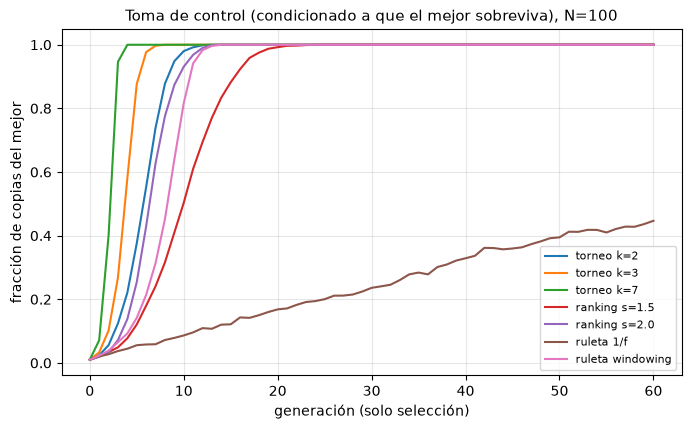

Generaciones hasta 99% de copias del mejor: {'torneo k=2': 11, 'torneo k=3': 7, 'torneo k=7': 4, 'ranking s=1.5': 20, 'ranking s=2.0': 12, 'ruleta 1/f': None, 'ruleta windowing': 13}
Orden de magnitud teórico para torneo, ln N / ln k: {2: 6.6, 3: 4.2, 7: 2.4}


In [3]:
def takeover(sel, N=100, gens=60, reps=30, seed=0):
    # fracción de la población que son copias del mejor, generación a generación (solo selección)
    r = np.random.default_rng(seed)
    out = np.zeros((reps, gens + 1))
    for q in range(reps):
        while True:                                       # se condiciona a que el mejor NO se extinga por azar al inicio
            f = r.uniform(100.5, 110, N); f[0] = 100.0    # un único mejor
            tray = []
            for t in range(gens + 1):
                tray.append(np.mean(f == 100.0))
                f = f[sel(f, N, r)]
                if tray[-1] == 0: break
            if tray[-1] > 0: break
        out[q] = tray
    return out.mean(axis=0)

esquemas = {"torneo k=2": lambda f, k, r: sel_tournament(f, k, r, 2),
            "torneo k=3": lambda f, k, r: sel_tournament(f, k, r, 3),
            "torneo k=7": lambda f, k, r: sel_tournament(f, k, r, 7),
            "ranking s=1.5": lambda f, k, r: sel_rank(f, k, r, 1.5),
            "ranking s=2.0": lambda f, k, r: sel_rank(f, k, r, 2.0),
            "ruleta 1/f": sel_roulette_inv,
            "ruleta windowing": sel_roulette_window}
fig, ax = plt.subplots(figsize=(8, 4.5))
tt = {}
for nombre, fn in esquemas.items():
    c = takeover(fn)
    ax.plot(c, label=nombre)
    hit = np.where(c >= 0.99)[0]
    tt[nombre] = int(hit[0]) if len(hit) else None
ax.set_xlabel("generación (solo selección)"); ax.set_ylabel("fracción de copias del mejor")
ax.set_title("Toma de control (condicionado a que el mejor sobreviva), N=100"); ax.legend(fontsize=8); plt.show()
print("Generaciones hasta 99% de copias del mejor:", tt)
print("Orden de magnitud teórico para torneo, ln N / ln k:", {k: round(math.log(100) / math.log(k), 1) for k in (2, 3, 7)})

**Lectura.** (Se condiciona a que el mejor no se extinga por azar en las primeras generaciones: con un solo individuo, aun una selección con presión tiene probabilidad apreciable de perderlo.) La toma de control se ordena según la presión: el torneo $k=7$ es el más rápido, seguido de $k=3$, mientras que el torneo $k=2$ y el ranking con $s\le2$ son suaves (tiempo de toma de control mayor). La ruleta con $1/f$ **prácticamente no ejerce presión** en este rango de costos (problema típico de usar aptitud proporcional sin reescalar). `None` significa que no alcanzó el 99% en el horizonte mostrado. La regla $\ln N/\ln k$ da el orden de magnitud para el torneo; el tiempo real es algo mayor porque incluye la fase inicial en que el mejor es una sola copia.

> Regla práctica: torneo de tamaño 2–5 o ranking con $s\approx1.5$–$2$ son opciones robustas; la ruleta pura solo es razonable si se controla la escala de la aptitud.

## 4. Cruce

### 4.1 Cruce binario
Sean $p_1,p_2\in\{0,1\}^n$.
- **1 punto**: se elige $c\in\{1,\dots,n-1\}$; $h_1=p_1[:c]\,|\,p_2[c:]$, $h_2=p_2[:c]\,|\,p_1[c:]$. Preserva bloques contiguos; tiene **sesgo posicional** (los extremos casi siempre se separan).
- **2 puntos**: se intercambia el segmento central; trata los extremos de forma más simétrica (el cromosoma es un anillo).
- **Uniforme**: cada gen se toma de $p_1$ o $p_2$ con prob. 1/2 (máscara aleatoria). Sin sesgo posicional pero muy disruptivo para bloques contiguos.

### 4.2 Cruce de permutaciones
Un cruce de un punto aplicado a permutaciones **produce duplicados**. Se necesitan operadores que garanticen factibilidad:
- **OX (Order Crossover, Davis 1985)**: copia un segmento de $p_1$ y completa con los genes restantes **en el orden relativo de $p_2$**. Preserva *orden relativo* y adyacencia dentro del segmento. Bueno para TSP.
- **PMX (Partially Mapped Crossover, Goldberg & Lingle 1985)**: el segmento viene de un padre y los conflictos se resuelven con la correspondencia (mapeo) entre los segmentos. Preserva *posiciones absolutas* de una parte importante de los genes del otro padre.
- **CX (Cycle Crossover)**: descompone el par de padres en ciclos de posiciones y alterna ciclos entre padres; **cada gen conserva la posición que tenía en alguno de los padres** (útil cuando la posición absoluta importa, p. ej. QAP).
- **ER (Edge Recombination, Whitley et al. 1989)**: construye una tabla de adyacencias (unión de las aristas de ambos padres) y arma el hijo prefiriendo la ciudad con **menos vecinos pendientes**; busca heredar el máximo de **aristas** de los padres. Pensado para TSP.

In [4]:
# ---------------- Cruces binarios (devuelven dos hijos) ----------------
def cx_1pt(a, b, rng):
    c = rng.integers(1, len(a))
    return np.r_[a[:c], b[c:]], np.r_[b[:c], a[c:]]

def cx_2pt(a, b, rng):
    i, j = np.sort(rng.choice(np.arange(1, len(a)), 2, replace=False))
    h1, h2 = a.copy(), b.copy()
    h1[i:j], h2[i:j] = b[i:j], a[i:j]
    return h1, h2

def cx_uniform(a, b, rng):
    m = rng.random(len(a)) < 0.5
    return np.where(m, a, b), np.where(m, b, a)

# ---------------- Cruces de permutaciones ----------------
def _cuts(n, rng, cuts):
    if cuts is not None:
        return cuts
    i, j = np.sort(rng.choice(n + 1, 2, replace=False))
    return int(i), int(j)

def ox_one(p1, p2, rng, cuts=None):
    # OX: segmento [a,b) de p1; el resto, en el orden de p2 comenzando después de b
    n = len(p1); a, b = _cuts(n, rng, cuts)
    child = np.full(n, -1); child[a:b] = p1[a:b]
    used = np.zeros(n, bool); used[p1[a:b]] = True
    rest = np.roll(p2, -b); rest = rest[~used[rest]]
    child[(np.arange(n - (b - a)) + b) % n] = rest
    return child

def pmx_one(p1, p2, rng, cuts=None):
    # PMX: el hijo es p1 salvo que en [a,b) toma los valores de p2; cada valor desplazado se
    # intercambia con la posición donde estaba el valor entrante (equivale a seguir el mapeo).
    n = len(p1); a, b = _cuts(n, rng, cuts)
    child = p1.copy(); pos = np.empty(n, int); pos[child] = np.arange(n)
    for i in range(a, b):
        v = p2[i]; j = pos[v]
        if j != i:
            u = child[i]
            child[i], child[j] = v, u
            pos[v], pos[u] = i, j
    return child

def er_one(p1, p2, rng):
    # Edge Recombination: tabla de adyacencias (circular) unión de ambos padres
    n = len(p1)
    adj = [set() for _ in range(n)]
    for p in (p1, p2):
        for i in range(n):
            u, v = int(p[i]), int(p[(i + 1) % n])
            adj[u].add(v); adj[v].add(u)
    cur = int(p1[0] if rng.random() < 0.5 else p2[0])
    unv = set(range(n)); unv.discard(cur)
    child = [cur]
    for _ in range(n - 1):
        for nb in adj[cur]:
            adj[nb].discard(cur)                  # cur ya fue usada: se quita de todas las listas
        cand = list(adj[cur])
        if cand:
            m = min(len(adj[c]) for c in cand)    # preferir la ciudad con menos vecinos pendientes
            cand = [c for c in cand if len(adj[c]) == m]
            nxt = cand[rng.integers(len(cand))]
        else:
            lst = list(unv); nxt = lst[rng.integers(len(lst))]
        unv.discard(nxt); child.append(nxt); cur = nxt
    return np.array(child)

def cycle_cx(p1, p2, rng):
    # CX: alterna ciclos; cada gen mantiene su posición de p1 o de p2
    n = len(p1); pos1 = np.empty(n, int); pos1[p1] = np.arange(n)
    h1, h2 = p1.copy(), p2.copy(); vis = np.zeros(n, bool); swap = False
    for s in range(n):
        if vis[s]: continue
        i = s
        while not vis[i]:
            vis[i] = True
            if swap: h1[i], h2[i] = p2[i], p1[i]
            i = pos1[p2[i]]
        swap = not swap
    return h1, h2

# versiones "par": devuelven dos hijos
def ox(p1, p2, rng):  return ox_one(p1, p2, rng), ox_one(p2, p1, rng)
def pmx(p1, p2, rng): return pmx_one(p1, p2, rng), pmx_one(p2, p1, rng)
def er(p1, p2, rng):  return er_one(p1, p2, rng), er_one(p1, p2, rng)

# ---------------- Ejemplo pequeño, con cortes fijos ----------------
P1 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9]) - 1
P2 = np.array([4, 5, 2, 1, 8, 7, 6, 9, 3]) - 1
show = lambda x: " ".join(str(int(v) + 1) for v in x)
print("Padre 1   :", show(P1)); print("Padre 2   :", show(P2))
print("OX  (cortes 3,6) :", show(ox_one(P1, P2, None, cuts=(3, 6))))
print("PMX (cortes 3,6) :", show(pmx_one(P1, P2, None, cuts=(3, 6))))
c1, c2 = cycle_cx(P1, P2, None)
print("CX  hijo 1 / 2   :", show(c1), "/", show(c2))
print("ER               :", show(er_one(P1, P2, np.random.default_rng(0))))

Padre 1   : 1 2 3 4 5 6 7 8 9
Padre 2   : 4 5 2 1 8 7 6 9 3
OX  (cortes 3,6) : 1 8 7 4 5 6 9 3 2
PMX (cortes 3,6) : 4 2 3 1 8 7 6 5 9
CX  hijo 1 / 2   : 1 5 2 4 8 6 7 9 3 / 4 2 3 1 5 7 6 8 9
ER               : 4 5 2 3 9 1 8 7 6


**Comprobación a mano.** Con cortes $[3,6)$ (posiciones 4 a 6, base 1): OX copia el segmento `4 5 6` de $P_1$ en esas posiciones y rellena el resto recorriendo $P_2$ de forma circular desde la posición 7, saltando los valores ya copiados. PMX toma el segmento `1 8 7` de $P_2$ en las posiciones 4 a 6 y los conflictos se resuelven con el mapeo $1\leftrightarrow4,\ 8\leftrightarrow5,\ 7\leftrightarrow6$ entre segmentos. Contrasta con la salida impresa. En lugar de confiar en el ojo, a continuación validamos **por propiedades**.

### Validación de operadores (permutación válida + propiedades características)

In [5]:
def es_perm(x, n):
    return len(x) == n and np.array_equal(np.sort(x), np.arange(n))

def aristas(t):
    n = len(t)
    return {frozenset((int(t[i]), int(t[(i + 1) % n]))) for i in range(n)}

rng = np.random.default_rng(7)
n = 40; T = 3000
stats = {k: {"validas": 0, "frac_aristas_heredadas": [], "frac_pos_heredadas": []} for k in ["OX", "PMX", "CX", "ER"]}
for _ in range(T):
    a, b = rng.permutation(n), rng.permutation(n)
    Ea, Eb = aristas(a), aristas(b)
    hijos = {"OX": ox(a, b, rng), "PMX": pmx(a, b, rng), "CX": cycle_cx(a, b, rng), "ER": er(a, b, rng)}
    for k, (h1, h2) in hijos.items():
        assert es_perm(h1, n) and es_perm(h2, n), f"{k} produjo un hijo inválido"
        stats[k]["validas"] += 2
        E = aristas(h1)
        stats[k]["frac_aristas_heredadas"].append(len(E & (Ea | Eb)) / n)
        stats[k]["frac_pos_heredadas"].append(np.mean((h1 == a) | (h1 == b)))
print("Todas las permutaciones producidas son válidas (assert superado para", T, "pares x 2 hijos x 4 operadores).")
tab = pd.DataFrame({k: {"hijos válidos": v["validas"],
                        "aristas heredadas de algún padre (media)": np.mean(v["frac_aristas_heredadas"]),
                        "genes en la misma posición que algún padre (media)": np.mean(v["frac_pos_heredadas"])}
                    for k, v in stats.items()}).T
print(tab.round(3))
# propiedad específica de CX: TODO gen conserva la posición de algún padre
a, b = rng.permutation(n), rng.permutation(n); h1, h2 = cycle_cx(a, b, rng)
print("CX: todo gen en posición de algún padre:", bool(np.all((h1 == a) | (h1 == b)) and np.all((h2 == a) | (h2 == b))))

Todas las permutaciones producidas son válidas (assert superado para 3000 pares x 2 hijos x 4 operadores).
     hijos válidos  aristas heredadas de algún padre (media)  \
OX          6000.0                                     0.810   
PMX         6000.0                                     0.726   
CX          6000.0                                     0.695   
ER          6000.0                                     0.964   

     genes en la misma posición que algún padre (media)  
OX                                               0.470   
PMX                                              0.839   
CX                                               1.000   
ER                                               0.085   
CX: todo gen en posición de algún padre: True


Los cuatro operadores producen siempre permutaciones válidas. La tabla muestra su "personalidad":
- **ER** hereda casi todas sus aristas de los padres (es su razón de ser: transmitir adyacencias, lo que importa en el TSP);
- **CX** transmite posiciones (por construcción, el 100% de los genes están en la posición de un padre);
- **OX** y **PMX** quedan en medio: heredan una buena parte de aristas/posiciones y mezclan el resto.

Los operadores de cruce **no tienen una jerarquía universal**: su calidad depende de si la propiedad que transmiten coincide con la que determina el costo del problema.

## 5. Mutación

La mutación introduce variación que el cruce no puede crear (alelos perdidos) y mantiene la diversidad.

| Operador | Efecto | Representación |
|---|---|---|
| Bit-flip (prob. $1/n$ por gen) | invierte bits independientemente | binaria |
| **Swap** | intercambia dos posiciones | permutación (cambio local pequeño: 4 aristas en TSP) |
| **Inversión** | invierte un segmento (como un movimiento 2-opt) | permutación (cambia 2 aristas; excelente en TSP) |
| **Scramble** | baraja aleatoriamente un segmento | permutación (más disruptivo) |

Con probabilidad por gen $p_m=1/n$ en binario, el número esperado de bits mutados por hijo es 1, y la probabilidad de no mutar nada es $(1-1/n)^n\approx e^{-1}$. En permutaciones, $p_m$ suele ser **por individuo** (aquí $p_m\in[0.2,0.4]$).

In [6]:
# ---------------- Mutaciones (devuelven una copia) ----------------
def mut_bitflip(x, rng, rate=None):
    rate = 1.0 / len(x) if rate is None else rate
    return x ^ (rng.random(len(x)) < rate).astype(x.dtype)

def mut_swap(t, rng):
    c = t.copy(); i, j = rng.choice(len(t), 2, replace=False)
    c[i], c[j] = c[j], c[i]
    return c

def mut_inversion(t, rng):
    c = t.copy(); i, j = np.sort(rng.choice(len(t), 2, replace=False))
    c[i:j + 1] = c[i:j + 1][::-1]
    return c

def mut_scramble(t, rng):
    c = t.copy(); i, j = np.sort(rng.choice(len(t), 2, replace=False))
    c[i:j + 1] = rng.permutation(c[i:j + 1])
    return c

# Validación: permutación válida y nº de aristas que cambian en el TSP
rng = np.random.default_rng(3); n = 40
cambios = {"swap": [], "inversión": [], "scramble": []}
for _ in range(2000):
    t = rng.permutation(n)
    for nombre, m in [("swap", mut_swap), ("inversión", mut_inversion), ("scramble", mut_scramble)]:
        h = m(t, rng); assert es_perm(h, n)
        cambios[nombre].append(len(aristas(t) - aristas(h)))
print("Aristas del tour que se pierden por mutación (media):", {k: round(np.mean(v), 2) for k, v in cambios.items()})
x = rng.integers(0, 2, 60).astype(np.int8)
print("Bits cambiados por bit-flip (media sobre 5000):", np.mean([(mut_bitflip(x, rng) != x).sum() for _ in range(5000)]).round(2), "(esperado 1.0)")

Aristas del tour que se pierden por mutación (media): {'swap': np.float64(3.78), 'inversión': np.float64(2.0), 'scramble': np.float64(13.75)}
Bits cambiados por bit-flip (media sobre 5000): 0.97 (esperado 1.0)


## 6. Reemplazo (supervivencia)

Tras generar $\lambda$ hijos desde una población de $\mu$ padres, el esquema de reemplazo decide quién sobrevive. En notación de estrategias evolutivas:

| Esquema | Regla | Comentario |
|---|---|---|
| **Generacional** ($\lambda=\mu$) | los hijos reemplazan a todos los padres | puede perder el mejor → se añade **elitismo** (se conservan los $e$ mejores padres) |
| **Estacionario** ($\lambda$ pequeño, p. ej. 2) | los hijos reemplazan a los peores | presión alta, convergencia rápida, riesgo de pérdida de diversidad |
| **$(\mu+\lambda)$** | los $\mu$ mejores de padres $\cup$ hijos | **elitista** (nunca empeora el mejor), pero un individuo bueno puede vivir para siempre |
| **$(\mu,\lambda)$**, $\lambda\ge\mu$ | los $\mu$ mejores de los hijos | **no elitista**: puede escapar de óptimos y, en ES, permite autoadaptar parámetros |

Para comparar justamente fijamos el **presupuesto de evaluaciones** (no el número de generaciones): un AG estacionario hace muchas más "generaciones" que uno generacional con el mismo costo.

### Motor genérico
El siguiente motor une los componentes (selección, cruce, mutación, reemplazo) y registra la curva del mejor valor vs. evaluaciones y, opcionalmente, la diversidad.

In [7]:
# ---------------- Diversidad de una población ----------------
def diversidad(pop, V):
    # pop: (N, L) con valores en {0..V-1}. Devuelve (distancia de Hamming media normalizada, entropía media por posición normalizada)
    N, L = pop.shape
    counts = np.zeros((L, V))
    np.add.at(counts, (np.broadcast_to(np.arange(L), pop.shape), pop), 1)
    acuerdos = (counts * (counts - 1) / 2).sum() / (L * N * (N - 1) / 2)    # prob. de que 2 individuos coincidan en una posición
    p = counts / N
    with np.errstate(divide="ignore", invalid="ignore"):
        H = -np.nansum(np.where(p > 0, p * np.log(p), 0.0), axis=1)
    return 1 - acuerdos, H.mean() / math.log(V)

# ---------------- Motor del AG ----------------
def run_ga(fit, init, cx, mut, sel, mu=80, evals=20000, pc=0.9, pm=0.3, lam=None, scheme="generacional",
           n_elite=1, seed=0, V=None, repair=None):
    # fit(x)->costo (minimizar) ; init(mu,rng)->(mu,L) ; cx(a,b,rng)->(h1,h2) ; mut(x,rng)->x' ; sel(f,k,rng)->índices.
    # scheme: 'generacional' (lam=mu, con n_elite), 'estacionario' (lam pequeño, reemplaza peores),
    #         'mu+lambda', 'mu,lambda' (requiere lam>=mu).
    rng = np.random.default_rng(seed)
    pop = init(mu, rng)
    if repair is not None: pop = np.array([repair(x) for x in pop])
    f = np.array([fit(x) for x in pop]); ne = mu
    lam = lam or (2 if scheme == "estacionario" else mu)
    ev_hist, best_hist, div_hist = [ne], [f.min()], []
    best_x, best_f = pop[f.argmin()].copy(), f.min()
    next_div = 0
    while ne < evals:
        if V is not None and ne >= next_div:
            div_hist.append(diversidad(pop, V)); next_div += mu
        L2 = lam + (lam % 2)
        pi = sel(f, L2, rng)
        kids = []
        for i in range(0, L2, 2):
            a, b = pop[pi[i]], pop[pi[i + 1]]
            h1, h2 = cx(a, b, rng) if rng.random() < pc else (a.copy(), b.copy())
            if rng.random() < pm: h1 = mut(h1, rng)
            if rng.random() < pm: h2 = mut(h2, rng)
            kids += [h1, h2]
        kids = np.array(kids[:lam])
        if repair is not None: kids = np.array([repair(x) for x in kids])
        kf = np.array([fit(x) for x in kids]); ne += lam
        if scheme == "generacional":
            e = np.argsort(f)[:n_elite]
            keep = np.argsort(kf)[:mu - n_elite]                  # se descartan los peores hijos para hacer sitio a la élite
            pop = np.vstack([pop[e], kids[keep]]); f = np.r_[f[e], kf[keep]]
        elif scheme == "estacionario":
            w = np.argsort(f)[-lam:]                              # los lam peores son reemplazados
            pop[w], f[w] = kids, kf
        elif scheme == "mu+lambda":
            U = np.vstack([pop, kids]); uf = np.r_[f, kf]; o = np.argsort(uf)[:mu]
            pop, f = U[o], uf[o]
        elif scheme == "mu,lambda":
            o = np.argsort(kf)[:mu]; pop, f = kids[o], kf[o]
        else:
            raise ValueError(scheme)
        if kf.min() < best_f: best_f, best_x = kf.min(), kids[kf.argmin()].copy()   # mejor histórico (los hijos son lo único nuevo)
        ev_hist.append(ne); best_hist.append(best_f)
    return dict(ev=np.array(ev_hist), best=np.array(best_hist), div=np.array(div_hist), x=best_x, f=best_f)

def curva_en_malla(res, grid):
    # mejor-hasta-ahora en una malla común de evaluaciones
    idx = np.searchsorted(res["ev"], grid, side="right") - 1
    return res["best"][np.clip(idx, 0, None)]

def init_perm(n):  return lambda mu, rng: np.argsort(rng.random((mu, n)), axis=1)
def init_bin(n):   return lambda mu, rng: rng.integers(0, 2, (mu, n)).astype(np.int8)

# Ejecución en paralelo (fork) con tareas descritas por claves -> evita serializar funciones
CTX = mp.get_context("fork")
def pmap(fn, tasks, procs=10):
    with CTX.Pool(min(procs, len(tasks))) as pool:
        return pool.map(fn, tasks, chunksize=1)

# prueba rápida del motor en TSP
r = run_ga(lambda t: tour_len(t, d40), init_perm(40), ox, mut_inversion, lambda f, k, r: sel_tournament(f, k, r, 3), evals=8000, seed=0, V=40)
assert es_perm(r["x"], 40) and abs(tour_len(r["x"], d40) - r["f"]) < 1e-9
print("Motor OK. Longitud encontrada:", round(r["f"], 1), "| nº puntos de diversidad:", len(r["div"]))

Motor OK. Longitud encontrada: 650.8 | nº puntos de diversidad: 99


> **Nota sobre el motor.** El motor registra el *mejor visto* (incluso en $(\mu,\lambda)$, donde la población puede empeorar, el reporte es el mejor histórico). La prueba al final del bloque verifica que el mejor devuelto es una permutación válida y que su costo coincide con una recomputación completa.

## 7. Diversidad

Medimos dos cantidades sobre $N$ individuos de longitud $L$ con alfabeto de tamaño $V$:

- **Distancia de Hamming media normalizada**: $\bar d=1-\frac{1}{L\binom N2}\sum_{j=1}^{L}\sum_{a}\binom{c_{ja}}{2}$, con $c_{ja}$ = nº de individuos con el valor $a$ en la posición $j$. Es la probabilidad de que dos individuos al azar difieran en una posición (en permutaciones, es una distancia posicional).
- **Entropía media por posición** (normalizada a $[0,1]$): $\bar H=\frac1{L\ln V}\sum_j\Big(-\sum_a p_{ja}\ln p_{ja}\Big)$.

Ambas valen ~1 en una población aleatoria y ~0 cuando la población colapsó a un solo individuo. Veamos cómo la presión selectiva y la mutación las afectan en el TSP. Calibramos primero el problema con referencias (aleatorio y búsqueda 2-opt multi-arranque) para saber qué es "bueno".

In [8]:
# ---------------- Referencias para el TSP: aleatorio y 2-opt multi-arranque ----------------
def two_opt(t, d, rng=None):
    # 2-opt de primera mejora con delta O(1); devuelve el tour localmente óptimo
    t = t.copy(); n = len(t); mejora = True
    while mejora:
        mejora = False
        for i in range(n - 1):
            for j in range(i + 2, n if i > 0 else n - 1):
                a, b, c, e = t[i], t[i + 1], t[j], t[(j + 1) % n]
                delta = d[a, c] + d[b, e] - d[a, b] - d[c, e]
                if delta < -1e-12:
                    t[i + 1:j + 1] = t[i + 1:j + 1][::-1]; mejora = True
    return t

# verificación: el delta de 2-opt coincide con la recomputación completa
rr = np.random.default_rng(5)
for _ in range(200):
    t = rr.permutation(40); i, j = np.sort(rr.choice(np.arange(0, 39), 2, replace=False))
    if j < i + 2: continue
    a, b, c, e = t[i], t[i + 1], t[j], t[(j + 1) % 40]
    delta = d40[a, c] + d40[b, e] - d40[a, b] - d40[c, e]
    t2 = t.copy(); t2[i + 1:j + 1] = t2[i + 1:j + 1][::-1]
    assert abs(tour_len(t2, d40) - tour_len(t, d40) - delta) < 1e-9
print("Delta 2-opt verificado contra recomputación completa.")

t0 = time.time()
ref_rand = np.mean([tour_len(rr.permutation(40), d40) for _ in range(300)])
ls = [tour_len(two_opt(rr.permutation(40), d40), d40) for _ in range(60)]
REF_2OPT_BEST, REF_2OPT_MEAN = min(ls), np.mean(ls)
print(f"Aleatorio: {ref_rand:.1f} | 2-opt desde aleatorio (60 arranques): media {REF_2OPT_MEAN:.1f}, mejor {REF_2OPT_BEST:.1f}  ({time.time()-t0:.1f}s)")

Delta 2-opt verificado contra recomputación completa.
Aleatorio: 2103.2 | 2-opt desde aleatorio (60 arranques): media 502.2, mejor 465.1  (0.1s)


(5s)


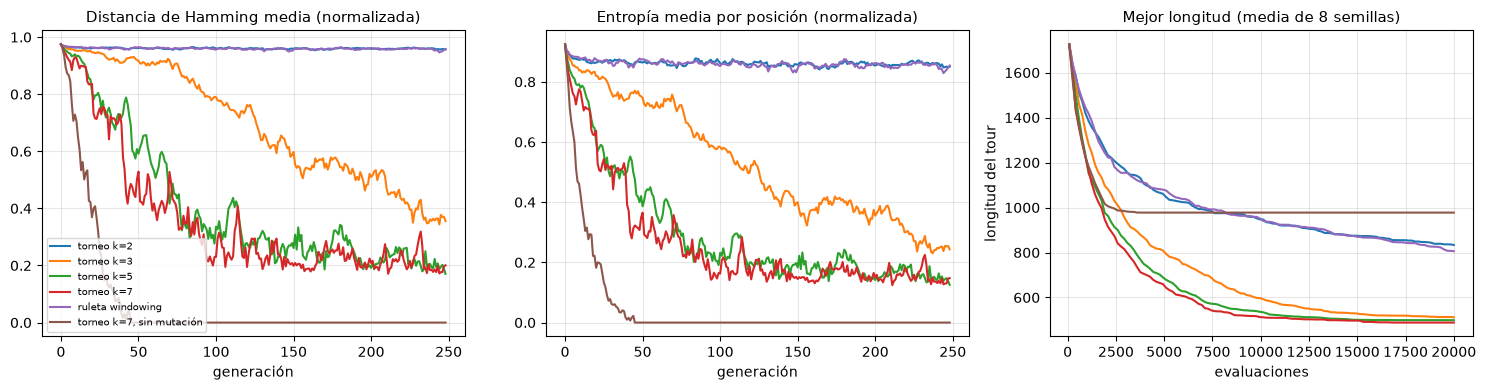

                          diversidad final (Hamming)  mejor final (media)
torneo k=2                                     0.957              833.506
torneo k=3                                     0.355              512.205
torneo k=5                                     0.171              499.233
torneo k=7                                     0.201              488.482
ruleta windowing                               0.958              805.794
torneo k=7, sin mutación                       0.000              977.508


In [9]:
# ---------------- Experimento de diversidad (TSP, OX + inversión, 20k evaluaciones) ----------------
FIT_TSP = lambda t: tour_len(t, d40)
SELS = {"torneo k=2": lambda f, k, r: sel_tournament(f, k, r, 2),
        "torneo k=3": lambda f, k, r: sel_tournament(f, k, r, 3),
        "torneo k=5": lambda f, k, r: sel_tournament(f, k, r, 5),
        "torneo k=7": lambda f, k, r: sel_tournament(f, k, r, 7),
        "ranking s=1.5": lambda f, k, r: sel_rank(f, k, r, 1.5),
        "ranking s=2.0": lambda f, k, r: sel_rank(f, k, r, 2.0),
        "ruleta 1/f": sel_roulette_inv,
        "ruleta windowing": sel_roulette_window}
MUTS = {"swap": mut_swap, "inversión": mut_inversion, "scramble": mut_scramble}
CXS = {"OX": ox, "PMX": pmx, "ER": er, "CX": cycle_cx}

# Cada experimento = dict de nombre -> kwargs (cadenas para operadores). EXP se fija antes de lanzar el pool.
EXP = {}
def tarea_tsp(task):
    nombre, seed = task
    c = dict(EXP[nombre])
    res = run_ga(FIT_TSP, init_perm(40), CXS[c.pop("cx", "OX")], MUTS[c.pop("mut", "inversión")],
                 SELS[c.pop("sel", "torneo k=3")], seed=seed, V=40, **c)
    return nombre, seed, res

GRID = np.linspace(80, 20000, 120)
def correr(exp, seeds, tarea=tarea_tsp, procs=10):
    global EXP; EXP = exp
    tasks = [(k, s) for k in exp for s in seeds]
    out = pmap(tarea, tasks, procs)
    R = {k: [] for k in exp}
    for k, s, res in out: R[k].append(res)
    return R

SEEDS = list(range(8))
t0 = time.time()
R_div = correr({"torneo k=2": dict(sel="torneo k=2", pm=0.3), "torneo k=3": dict(sel="torneo k=3", pm=0.3),
                "torneo k=5": dict(sel="torneo k=5", pm=0.3), "torneo k=7": dict(sel="torneo k=7", pm=0.3),
                "ruleta windowing": dict(sel="ruleta windowing", pm=0.3),
                "torneo k=7, sin mutación": dict(sel="torneo k=7", pm=0.0)}, SEEDS)
print(f"({time.time()-t0:.0f}s)")
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for k, L in R_div.items():
    D = np.array([r["div"][:min(len(x["div"]) for x in L)] for r in L])
    axs[0].plot(D[:, :, 0].mean(0), label=k); axs[1].plot(D[:, :, 1].mean(0), label=k)
    axs[2].plot(GRID, np.mean([curva_en_malla(r, GRID) for r in L], axis=0), label=k)
axs[0].set_title("Distancia de Hamming media (normalizada)"); axs[1].set_title("Entropía media por posición (normalizada)")
axs[2].set_title("Mejor longitud (media de 8 semillas)")
for a, x in zip(axs, ["generación", "generación", "evaluaciones"]): a.set_xlabel(x)
axs[2].set_ylabel("longitud del tour"); axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()
print(pd.DataFrame({k: {"diversidad final (Hamming)": np.mean([r["div"][-1, 0] for r in L]),
                         "mejor final (media)": np.mean([r["f"] for r in L])} for k, L in R_div.items()}).T.round(3))

**Lectura.** (Contrastar con la tabla y las figuras de arriba.) La diversidad cae más rápido cuanto mayor es la presión selectiva; las selecciones suaves (torneo $k=2$, ruleta con windowing) mantienen la población casi tan diversa como una aleatoria durante las 250 generaciones, es decir, **no convergen en este presupuesto** (no contradice el tiempo de toma de control de la sección 3: allí solo hay selección, mientras que aquí cruce y mutación reponen variación en cada generación y el "mejor" va cambiando), y por eso su mejor longitud final es mucho peor. Sin mutación el colapso es total (diversidad 0): la población pierde todo material genético nuevo y el progreso se detiene en un valor peor que con mutación. Con mutación, la diversidad se estabiliza en un valor positivo (equilibrio entre selección y mutación). La relación entre diversidad y calidad **no es monótona**: demasiada diversidad desperdicia evaluaciones y demasiado poca estanca la búsqueda. Este compromiso es la razón de ser del ajuste de parámetros ([notebook 15](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb)) y de los mecanismos de gestión de diversidad que veremos en el [notebook 10](10-brkga-memeticos-scatter-search.ipynb).

## 8. Teorema de esquemas (discusión crítica)

Un **esquema** $H$ es una plantilla sobre $\{0,1,*\}^n$ (p. ej. `11***0**`). Su **orden** $o(H)$ es el nº de posiciones fijas y su **longitud de definición** $\delta(H)$ la distancia entre la primera y la última posición fija. Para un AG con selección proporcional, cruce de un punto (prob. $p_c$) y mutación por bit ($p_m$), Holland (1975) demostró que el número esperado de instancias de $H$ satisface

$$\mathbb{E}\,[m(H,t+1)]\;\ge\;m(H,t)\;\frac{f(H,t)}{\bar f(t)}\Big[1-p_c\frac{\delta(H)}{n-1}-o(H)\,p_m\Big],$$

donde $f(H,t)$ es la aptitud media de las instancias de $H$ y $\bar f(t)$ la de toda la población. La lectura clásica: *los esquemas cortos, de bajo orden y de aptitud superior al promedio crecen exponencialmente* (los "bloques constructores", Goldberg 1989).

### Verificación empírica en OneMax
En OneMax ($f(x)=\sum x_i$, maximizar) el esquema $H=$ `111*...*` tiene orden 3, $\delta=2$ y aptitud superior al promedio. Promediamos 200 corridas de un AG simple con ruleta, cruce 1 punto y bit-flip, y comparamos el valor medido $m(H,t+1)$ con la cota calculada **paso a paso** a partir de los valores medidos en $t$.

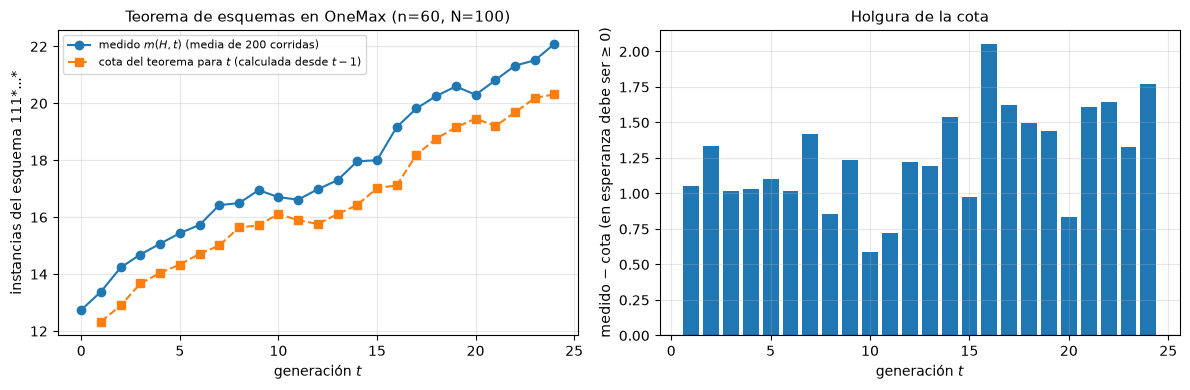

Fracción de generaciones con (media medida) >= (media de la cota): 1.0
Valor inicial de m(H,0): 12.74 (esperado N/2^3 = 12.5)


In [10]:
def ga_simple_onemax(n=60, N=100, gens=25, pc=0.9, pm=None, seed=0, k=3):
    # AG generacional sin elitismo, ruleta (aptitud = nº de unos), cruce 1 punto, bit-flip. Todo vectorizado.
    pm = 1.0 / n if pm is None else pm
    r = np.random.default_rng(seed)
    pop = r.integers(0, 2, (N, n)).astype(np.int8)
    m_obs, bound, fH_l, fbar_l = [], [], [], []
    for t in range(gens):
        fit = pop.sum(1).astype(float)
        inH = pop[:, :k].all(axis=1)                  # el esquema fija los primeros k bits en 1
        m = inH.sum(); m_obs.append(m)
        fH = fit[inH].mean() if m else 0.0; fbar = fit.mean()
        bound.append(m * (fH / fbar) * (1 - pc * (k - 1) / (n - 1) - k * pm))
        fH_l.append(fH); fbar_l.append(fbar)
        pi = r.choice(N, size=N, p=fit / fit.sum())
        A, B = pop[pi[0::2]], pop[pi[1::2]]
        cut = r.integers(1, n, N // 2)[:, None]
        do = (r.random(N // 2) < pc)[:, None]
        mask = (np.arange(n)[None, :] < cut) | ~do
        C1 = np.where(mask, A, B); C2 = np.where(mask, B, A)
        pop = np.vstack([C1, C2])
        pop ^= (r.random(pop.shape) < pm).astype(np.int8)
    return np.array(m_obs), np.array(bound)

runs = [ga_simple_onemax(seed=s) for s in range(200)]
M = np.array([r[0] for r in runs]); B = np.array([r[1] for r in runs])
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(M.mean(0), "o-", label="medido $m(H,t)$ (media de 200 corridas)")
axs[0].plot(np.r_[np.nan, B.mean(0)[:-1]], "s--", label="cota del teorema para $t$ (calculada desde $t-1$)")
axs[0].set_xlabel("generación $t$"); axs[0].set_ylabel("instancias del esquema 111*...*"); axs[0].legend(fontsize=8)
axs[0].set_title("Teorema de esquemas en OneMax (n=60, N=100)")
holgura = M.mean(0)[1:] - B.mean(0)[:-1]
axs[1].bar(range(1, len(holgura) + 1), holgura); axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xlabel("generación $t$"); axs[1].set_ylabel("medido − cota (en esperanza debe ser ≥ 0)")
axs[1].set_title("Holgura de la cota"); plt.tight_layout(); plt.show()
print("Fracción de generaciones con (media medida) >= (media de la cota):", np.mean(holgura >= 0).round(2))
print("Valor inicial de m(H,0):", M[:, 0].mean().round(2), "(esperado N/2^3 = 12.5)")

**Lectura y crítica.** La cota se cumple (es una desigualdad en esperanza, así que *se cumple* con holgura) pero:

1. **Es solo una cota inferior de un paso**: no dice nada sobre cuántas instancias nuevas se *crean* por cruce/mutación (en la figura, la holgura es grande porque el cruce **construye** instancias de $H$ que la cota ignora).
2. **No predice la dinámica a largo plazo**: $f(H,t)/\bar f(t)$ cambia con el tiempo (a medida que el promedio sube, la ventaja del esquema se reduce) y $m(H,t)$ real es una variable aleatoria; extrapolar "crecimiento exponencial" es un error.
3. **No explica por qué el AG encuentra óptimos**: la *hipótesis de los bloques constructores* (que el AG ensambla soluciones óptimas con esquemas cortos y de aptitud superior) es una conjetura que falla con *engaño* (*deception*) y con epistasis fuerte; además depende de la representación.
4. **Solo cubre selección proporcional + cruce de un punto**; para torneo, ranking, OX/PMX, etc., hay generalizaciones (Radcliffe, Poli; modelos exactos de Vose 1999), pero no dan una teoría de convergencia simple.
5. Se apoya en poblaciones infinitas/esperanzas; los efectos de **deriva genética** en poblaciones finitas son importantes.

Valor real: es una **explicación cualitativa** del compromiso entre explotación (selección) y disrupción (cruce largo, mutación alta); como teoría predictiva ha sido ampliamente cuestionada.

## 9. AG sobre el TSP: comparación de operadores

Fijamos un presupuesto de **20 000 evaluaciones**, $\mu=80$, $p_c=0.9$, $p_m=0.3$ (por hijo), y 8 semillas por configuración. La configuración base es **OX + inversión + torneo $k=3$ + generacional con elitismo 1**; en cada comparación cambiamos un componente. Reportamos media $\pm$ desviación de la mejor longitud final y las curvas de convergencia.

Importante: las comparaciones usan la **misma instancia** y las mismas semillas por configuración, así que las diferencias reflejan el operador y la variabilidad entre semillas (la desviación estándar nos indica cuándo una diferencia es ruido).

Tiempo de las 3 comparaciones: 14s


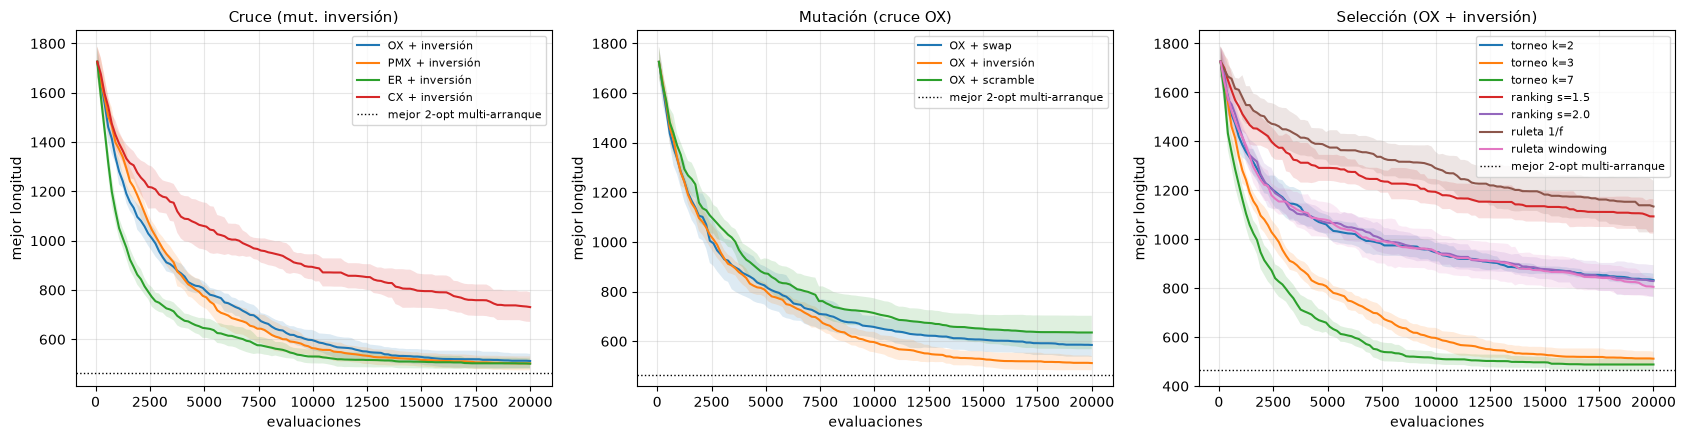

Referencias: aleatorio 2103.2 | 2-opt multi-arranque: media 502.2 , mejor 465.1

(a) Cruce
                   media  desv.   mejor    peor  % sobre ref.
OX + inversión   512.21  28.66  480.54  557.68         10.14
PMX + inversión  502.59  28.23  471.58  551.36          8.07
ER + inversión   501.32  20.80  465.06  519.61          7.80
CX + inversión   730.79  59.98  654.62  793.79         57.14

(b) Mutación
                  media  desv.   mejor    peor  % sobre ref.
OX + swap       585.23  48.35  507.93  648.44         25.84
OX + inversión  512.21  28.66  480.54  557.68         10.14
OX + scramble   635.45  67.41  533.53  754.32         36.64

(c) Selección
                     media   desv.   mejor     peor  % sobre ref.
torneo k=2         833.51   25.79  786.50   866.78         79.22
torneo k=3         512.21   28.66  480.54   557.68         10.14
torneo k=7         488.48   23.80  465.06   523.83          5.04
ranking s=1.5     1093.52   70.41  968.27  1176.28        135.13
ranking

In [11]:
def tabla(R, ref=None):
    rows = {}
    for k, L in R.items():
        v = np.array([r["f"] for r in L])
        rows[k] = {"media": v.mean(), "desv.": v.std(ddof=1), "mejor": v.min(), "peor": v.max()}
    df = pd.DataFrame(rows).T
    if ref: df["% sobre ref."] = 100 * (df["media"] / ref - 1)
    return df.round(2)

def graf_conv(R, titulo, ax=None, ref=None):
    ax = ax or plt.subplots(figsize=(8, 4.5))[1]
    for k, L in R.items():
        C = np.array([curva_en_malla(r, GRID) for r in L]); m, s = C.mean(0), C.std(0, ddof=1)
        ax.plot(GRID, m, label=k); ax.fill_between(GRID, m - s, m + s, alpha=0.15)
    if ref: ax.axhline(ref, color="k", ls=":", lw=1, label="mejor 2-opt multi-arranque")
    ax.set_xlabel("evaluaciones"); ax.set_ylabel("mejor longitud"); ax.set_title(titulo); ax.legend(fontsize=8)
    return ax

t0 = time.time()
# --- (a) Cruce ---
R_cx = correr({f"{c} + inversión": dict(cx=c, mut="inversión", sel="torneo k=3") for c in ["OX", "PMX", "ER", "CX"]}, SEEDS)
# --- (b) Mutación ---
R_mut = correr({f"OX + {m}": dict(cx="OX", mut=m, sel="torneo k=3") for m in ["swap", "inversión", "scramble"]}, SEEDS)
# --- (c) Selección ---
R_sel = correr({s: dict(cx="OX", mut="inversión", sel=s) for s in ["torneo k=2", "torneo k=3", "torneo k=7", "ranking s=1.5", "ranking s=2.0", "ruleta 1/f", "ruleta windowing"]}, SEEDS)
print(f"Tiempo de las 3 comparaciones: {time.time()-t0:.0f}s")
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
graf_conv(R_cx, "Cruce (mut. inversión)", axs[0], REF_2OPT_BEST); graf_conv(R_mut, "Mutación (cruce OX)", axs[1], REF_2OPT_BEST)
graf_conv(R_sel, "Selección (OX + inversión)", axs[2], REF_2OPT_BEST); plt.tight_layout(); plt.show()
print("Referencias: aleatorio", round(ref_rand, 1), "| 2-opt multi-arranque: media", round(REF_2OPT_MEAN, 1), ", mejor", round(REF_2OPT_BEST, 1))
print("\n(a) Cruce\n", tabla(R_cx, REF_2OPT_BEST)); print("\n(b) Mutación\n", tabla(R_mut, REF_2OPT_BEST)); print("\n(c) Selección\n", tabla(R_sel, REF_2OPT_BEST))

**Lectura (contrastada con las tablas de arriba).** Compara las medias *en unidades de la desviación* antes de declarar un ganador.
- **Cruce**: OX, PMX y ER quedan dentro de una desviación entre sí (diferencias no concluyentes con 8 semillas); CX es claramente peor, coherente con que transmite posiciones, no aristas (tabla de la sección 4: solo ~70% de sus aristas vienen de los padres, frente a ~96% en ER).
- **Mutación**: la **inversión** (equivale a un movimiento 2-opt: cambia solo 2 aristas) supera con claridad a swap y scramble; scramble es la más disruptiva (pierde ~14 aristas).
- **Selección**: con 250 generaciones, la presión alta (torneo $k=7$) gana; las selecciones suaves (torneo $k=2$, ranking $s\le2$, ruleta) no convergen a tiempo, y la ruleta sobre $1/f$ es la peor porque su presión es casi nula. Con presupuestos mucho mayores las selecciones suaves alcanzarían mejores resultados finales; el ranking óptimo depende del presupuesto.

Un AG "puro" (sin búsqueda local) queda típicamente por detrás de un 2-opt multi-arranque en TSP con este presupuesto: la combinación AG + búsqueda local (algoritmo memético) se estudia en el [notebook 10](10-brkga-memeticos-scatter-search.ipynb).

### Comparación de esquemas de reemplazo

(5s)


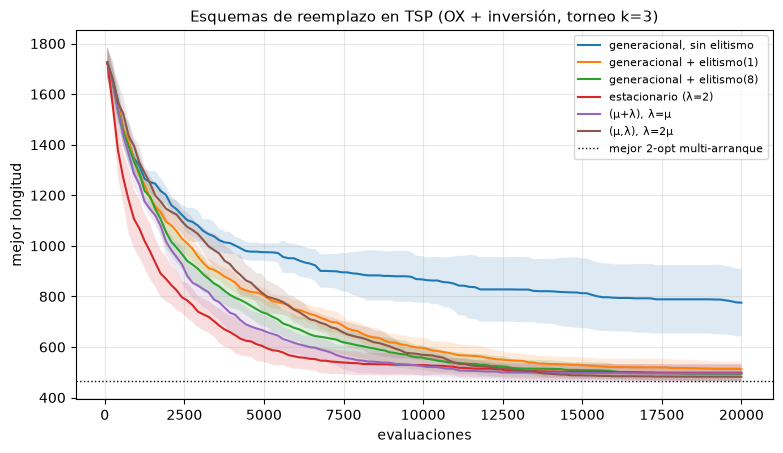

                             media   desv.   mejor    peor  % sobre ref.
generacional, sin elitismo  775.47  133.37  489.53  896.35         66.75
generacional + elitismo(1)  512.21   28.66  480.54  557.68         10.14
generacional + elitismo(8)  493.76   27.89  469.77  541.67          6.17
estacionario (λ=2)          498.52   33.21  469.25  548.94          7.19
(μ+λ), λ=μ                  495.57   36.67  465.06  562.13          6.56
(μ,λ), λ=2μ                 482.50   14.18  466.78  513.27          3.75
generacional, sin elitismo    0.867
generacional + elitismo(1)    0.355
generacional + elitismo(8)    0.109
estacionario (λ=2)            0.001
(μ+λ), λ=μ                    0.000
(μ,λ), λ=2μ                   0.006
Name: Hamming final, dtype: float64


In [12]:
t0 = time.time()
R_rep = correr({
    "generacional, sin elitismo": dict(scheme="generacional", n_elite=0),
    "generacional + elitismo(1)": dict(scheme="generacional", n_elite=1),
    "generacional + elitismo(8)": dict(scheme="generacional", n_elite=8),
    "estacionario (λ=2)": dict(scheme="estacionario"),
    "(μ+λ), λ=μ": dict(scheme="mu+lambda"),
    "(μ,λ), λ=2μ": dict(scheme="mu,lambda", lam=160),
}, SEEDS)
print(f"({time.time()-t0:.0f}s)")
fig, ax = plt.subplots(figsize=(9, 4.8)); graf_conv(R_rep, "Esquemas de reemplazo en TSP (OX + inversión, torneo k=3)", ax, REF_2OPT_BEST); plt.show()
print(tabla(R_rep, REF_2OPT_BEST))
# Diversidad final por esquema
print(pd.Series({k: np.mean([r["div"][-1, 0] for r in L]) for k, L in R_rep.items()}, name="Hamming final").round(3))

Con presupuesto fijo, los esquemas **elitistas o de truncación** (elitismo, $(\mu+\lambda)$, estacionario, $(\mu,\lambda)$ con $\lambda=2\mu$) convergen mucho más rápido que el generacional sin elitismo, a costa de perder diversidad (última tabla: la diversidad final es casi 0 en los tres últimos). El generacional sin elitismo pierde al mejor individuo en cada generación y progresa mal (el reporte usa el mejor histórico, pero la población no lo aprovecha). Nótese que $(\mu,\lambda)$ con $\lambda=2\mu$ aplica una **truncación fuerte** (se queda con la mitad superior de los hijos), así que su buen resultado aquí refleja principalmente alta presión selectiva efectiva, no una ventaja intrínseca de "coma" sobre "más". Entre elitismo(1), elitismo(8), estacionario y $(\mu+\lambda)$ las diferencias están dentro de una desviación. No existe un ganador universal: depende del presupuesto y de cuán multimodal sea el paisaje.

### Visualización: el mejor tour del AG vs. la referencia 2-opt

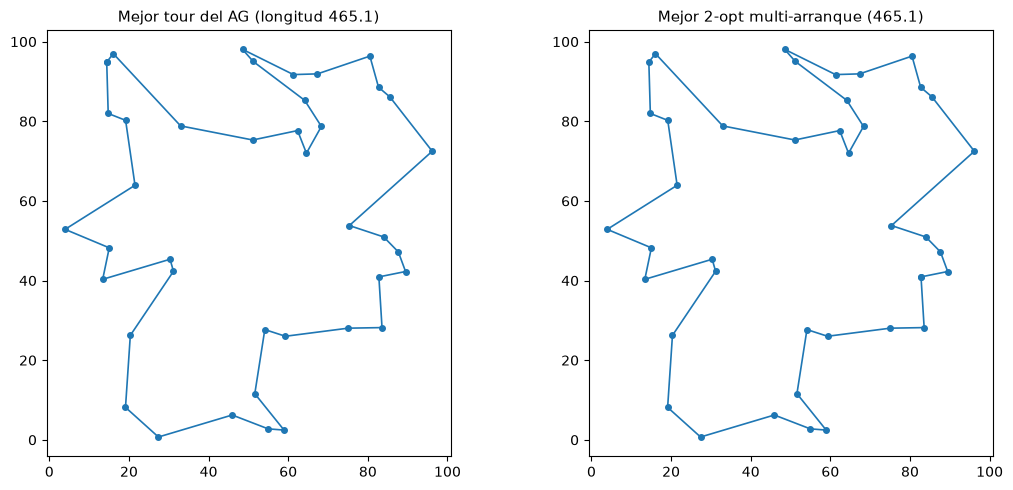

In [13]:
mejor_ga = min((r for L in R_cx.values() for r in L), key=lambda r: r["f"])
t2 = two_opt(np.random.default_rng(11).permutation(40), d40)
for _ in range(60):
    c = two_opt(np.random.default_rng(100 + _).permutation(40), d40)
    if tour_len(c, d40) < tour_len(t2, d40): t2 = c
assert es_perm(mejor_ga["x"], 40) and abs(tour_len(mejor_ga["x"], d40) - mejor_ga["f"]) < 1e-9   # verificación de correctitud
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
plot_tour(xy40, mejor_ga["x"], axs[0], f"Mejor tour del AG (longitud {mejor_ga['f']:.1f})")
plot_tour(xy40, t2, axs[1], f"Mejor 2-opt multi-arranque ({tour_len(t2, d40):.1f})"); plt.tight_layout(); plt.show()

## 10. AG sobre el QAP: por qué el cruce debe respetar la estructura del problema

En el QAP la permutación $p$ asigna la instalación $i$ al sitio $p_i$ y el costo $\sum_{ij}F_{ij}D_{p_ip_j}$ depende de **posiciones absolutas**, no de adyacencias cíclicas. Cabe esperar que **CX/PMX** (que transmiten posiciones) funcionen mejor que **ER** (diseñado para aristas, que aquí no tiene significado). Probamos con $n=15$, presupuesto 15 000 evaluaciones, y además comparamos con un baseline justo: *descenso por intercambios de pares con reinicios aleatorios* al mismo presupuesto, y búsqueda aleatoria pura.

(4s)
                                          media  desv.   mejor    peor
PMX + swap                               952.50  24.04   914.0   980.0
CX + swap                                962.50  30.91   920.0  1020.0
OX + swap                                964.00  28.30   922.0  1008.0
ER + swap                                967.25  21.00   946.0  1012.0
búsqueda aleatoria (mismo presupuesto)  1055.25  19.85  1028.0  1080.0
descenso 2-swap con reinicios            920.00   3.85   914.0   924.0


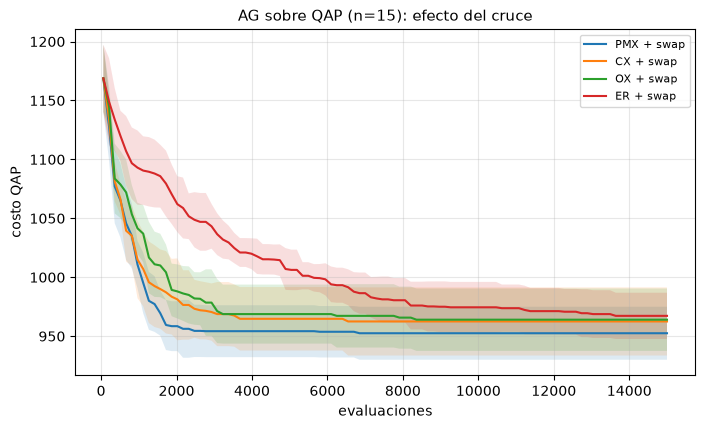

In [14]:
FIT_QAP = lambda p: qap_cost(p, F15, D15)
def tarea_qap(task):
    nombre, seed = task
    c = dict(EXP[nombre])
    res = run_ga(FIT_QAP, init_perm(15), CXS[c.pop("cx")], MUTS[c.pop("mut", "swap")], SELS["torneo k=3"], mu=60,
                 evals=15000, seed=seed, V=15, **c)
    return nombre, seed, res

def descenso_swaps(p, budget, F, D, rng):
    # descenso de primera mejora sobre swaps (recomputa costo completo); consume 'budget' evaluaciones como máximo
    cur = qap_cost(p, F, D); used = 1; n = len(p); mejora = True
    while mejora and used < budget:
        mejora = False
        for i, j in rng.permutation(np.array(list(combinations(range(n), 2)))):
            q = p.copy(); q[i], q[j] = q[j], q[i]; c = qap_cost(q, F, D); used += 1
            if c < cur: p, cur, mejora = q, c, True; break
            if used >= budget: break
    return p, cur, used

def baseline_qap(seed, budget=15000):
    rng = np.random.default_rng(seed); usados = 0; mejor = np.inf; rand_best = np.inf
    for _ in range(budget): rand_best = min(rand_best, qap_cost(rng.permutation(15), F15, D15))
    while usados < budget:
        p, c, u = descenso_swaps(rng.permutation(15), budget - usados, F15, D15, rng); usados += u; mejor = min(mejor, c)
    return rand_best, mejor

t0 = time.time()
R_qap = correr({f"{c} + swap": dict(cx=c, mut="swap") for c in ["PMX", "CX", "OX", "ER"]}, SEEDS, tarea=tarea_qap)
base = [baseline_qap(s) for s in SEEDS]
rand_v, desc_v = np.array([b[0] for b in base]), np.array([b[1] for b in base])
print(f"({time.time()-t0:.0f}s)")
df = tabla(R_qap)
df.loc["búsqueda aleatoria (mismo presupuesto)"] = [rand_v.mean(), rand_v.std(ddof=1), rand_v.min(), rand_v.max()]
df.loc["descenso 2-swap con reinicios"] = [desc_v.mean(), desc_v.std(ddof=1), desc_v.min(), desc_v.max()]
print(df.round(2))
GRID_Q = np.linspace(60, 15000, 100)
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, L in R_qap.items():
    C = np.array([curva_en_malla(r, GRID_Q) for r in L]); ax.plot(GRID_Q, C.mean(0), label=k); ax.fill_between(GRID_Q, C.mean(0) - C.std(0), C.mean(0) + C.std(0), alpha=0.15)
ax.set_xlabel("evaluaciones"); ax.set_ylabel("costo QAP"); ax.set_title("AG sobre QAP (n=15): efecto del cruce"); ax.legend(fontsize=8); plt.show()
# verificación de factibilidad de las soluciones finales
assert all(es_perm(r["x"], 15) and qap_cost(r["x"], F15, D15) == r["f"] for L in R_qap.values() for r in L)

**Lectura.** Todos los AG superan con claridad a la búsqueda aleatoria, pero **las diferencias entre cruces (PMX, CX, OX, ER) están dentro de una desviación estándar**: con $n=15$, 60 individuos y 15 000 evaluaciones no podemos afirmar que los operadores posicionales superen a ER; la hipótesis "el cruce debe respetar la estructura" no se ve confirmada de forma concluyente en esta escala (PMX tiene la media más baja, ER la más alta, pero con diferencias menores que el ruido). Más llamativo: el **descenso por swaps con reinicios supera a todos los AG** con el mismo presupuesto y con mucha menor varianza (es una búsqueda local sobre un vecindario de solo 105 swaps en un espacio pequeño). Lección: **el AG no es gratis**; en espacios pequeños una búsqueda local multi-arranque es un baseline muy duro, y el AG gana terreno cuando el espacio es grande y el cruce transmite estructura útil, sobre todo combinado con búsqueda local (memético, [notebook 10](10-brkga-memeticos-scatter-search.ipynb)). Para que ese cruce funcione en QAP sin heurísticas de reparación, los *random keys* del [notebook 10](10-brkga-memeticos-scatter-search.ipynb) son una alternativa elegante.

## 11. AG binario sobre la mochila (con óptimo exacto)

Mochila 0/1: maximizar $\sum v_ix_i$ sujeto a $\sum w_ix_i\le C$. Los hijos de un cruce binario pueden **violar la capacidad**. Dos manejos clásicos:

- **Penalización**: $f(x)=-\big(\sum v_ix_i-\rho\,\max(0,\sum w_ix_i-C)\big)$.
- **Reparación (Lamarckiana)**: si el peso excede $C$, se eliminan ítems en orden creciente de $v_i/w_i$ hasta ser factible; el individuo reparado reemplaza al original.

Como el óptimo se obtiene exactamente por programación dinámica, podemos medir la **brecha real**. Comparamos cruce 1 punto / 2 puntos / uniforme y penalización vs. reparación (8 semillas, 15 000 evaluaciones).

Reparador verificado: siempre factible y solo elimina ítems.


(2s) Óptimo exacto (DP) = 1301
                         valor medio  desv.  brecha media %  óptimos hallados
1 punto / penalización       1283.25  23.27            1.36                 0
1 punto / reparación         1297.75   1.39            0.25                 0
2 puntos / penalización      1289.12  11.89            0.91                 1
2 puntos / reparación        1296.25   3.15            0.37                 1
uniforme / penalización      1297.00   2.14            0.31                 0
uniforme / reparación        1298.38   2.77            0.20                 1


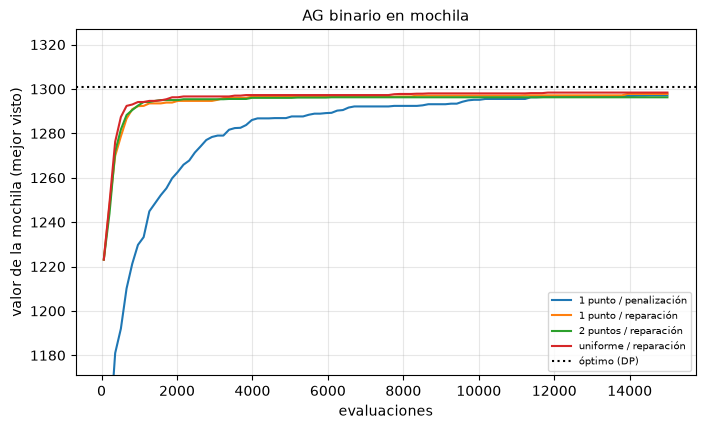

In [15]:
OPT_K = knap_dp(w_k, v_k, cap_k)
orden_ratio = np.argsort(v_k / w_k)                 # ascendente: primero se eliminan los de peor relación valor/peso
w_ord = w_k[orden_ratio]

def reparar(x):
    # elimina ítems de menor v/w hasta cumplir la capacidad (vectorizado con cumsum). Devuelve copia factible.
    x = x.copy(); exceso = (w_k * x).sum() - cap_k
    if exceso > 0:
        quitados = np.cumsum(w_ord * x[orden_ratio])
        kcut = np.searchsorted(quitados, exceso)             # primer prefijo cuyo peso removido cubre el exceso
        x[orden_ratio[:kcut + 1]] = 0
    return x

def fit_knap_pen(x, rho=3.0):
    exceso = max(0, (w_k * x).sum() - cap_k)
    return -((v_k * x).sum() - rho * exceso)

def fit_knap_rep(x):
    return -float((v_k * x).sum())                  # asume x ya reparado

# verificación del reparador
rr = np.random.default_rng(1)
for _ in range(2000):
    x = rr.integers(0, 2, 60).astype(np.int8); y = reparar(x)
    assert (w_k * y).sum() <= cap_k and np.all(y <= x)
print("Reparador verificado: siempre factible y solo elimina ítems.")

CXB = {"1 punto": cx_1pt, "2 puntos": cx_2pt, "uniforme": cx_uniform}
def tarea_knap(task):
    nombre, seed = task
    c = dict(EXP[nombre]); modo = c.pop("modo")
    fit = fit_knap_rep if modo == "reparación" else fit_knap_pen
    res = run_ga(fit, init_bin(60), CXB[c.pop("cx")], lambda x, r: mut_bitflip(x, r), SELS["torneo k=3"], mu=60, evals=15000,
                 pm=1.0, seed=seed, V=2, repair=reparar if modo == "reparación" else None, **c)
    x = reparar(res["x"]); res["valor_factible"] = (v_k * x).sum()
    return nombre, seed, res

t0 = time.time()
R_k = correr({f"{c} / {m}": dict(cx=c, modo=m) for c in CXB for m in ["penalización", "reparación"]}, SEEDS, tarea=tarea_knap)
print(f"({time.time()-t0:.0f}s) Óptimo exacto (DP) = {OPT_K}")
rows = {}
for k, L in R_k.items():
    v = np.array([r["valor_factible"] for r in L]); rows[k] = {"valor medio": v.mean(), "desv.": v.std(ddof=1), "brecha media %": 100 * (1 - v.mean() / OPT_K),
                                                                "óptimos hallados": int((v == OPT_K).sum())}
dfk = pd.DataFrame(rows).T.round(2); dfk["óptimos hallados"] = dfk["óptimos hallados"].astype(int); print(dfk)
fig, ax = plt.subplots(figsize=(8, 4.5))
GRID_K = np.linspace(60, 15000, 100)
for k, L in R_k.items():
    if k.endswith("reparación") or k.startswith("1 punto"):
        C = -np.array([curva_en_malla(r, GRID_K) for r in L]); ax.plot(GRID_K, C.mean(0), label=k)
ax.axhline(OPT_K, color="k", ls=":", label="óptimo (DP)"); ax.set_ylim(OPT_K * 0.9, OPT_K * 1.02)
ax.set_xlabel("evaluaciones"); ax.set_ylabel("valor de la mochila (mejor visto)"); ax.set_title("AG binario en mochila"); ax.legend(fontsize=7); plt.show()

**Lectura.** (Para la penalización, el valor de la tabla se reporta *tras repararlo* para ser comparable.) La brecha respecto al óptimo exacto es directamente interpretable: todas las variantes quedan por debajo del 1.5% del óptimo. Con **reparación** los tres cruces dan resultados muy parecidos y con baja varianza; con **penalización** el resultado depende más del cruce y la dispersión entre semillas es mayor (en particular el cruce de 1 punto). La elección de $\rho$ en la penalización es delicada (muy bajo: el AG converge a infactibles; muy alto: la frontera factible se vuelve una "pared"), mientras que la reparación no tiene ese parámetro. El orden de los ítems en el cromosoma es arbitrario, de modo que el sesgo posicional del cruce de 1 punto no tiene justificación en este problema y el cruce uniforme es una opción neutral.

## 12. Estrategias evolutivas (ES)

Las **estrategias evolutivas** (Rechenberg, Schwefel) nacieron para optimización continua. El individuo es $(x,\sigma)$: el vector de decisión **y** el tamaño de paso, que evoluciona (*autoadaptación*). La mutación es gaussiana: $x'=x+\sigma\,\mathcal N(0,I)$.

- **$(1+1)$-ES con regla del 1/5** (Rechenberg): si más de 1/5 de las mutaciones mejoran, aumentar $\sigma$; si menos, disminuir. Motivación: en la esfera la tasa de éxito óptima ronda 0.2.
- **$(\mu/\mu,\lambda)$-ES** con autoadaptación isotrópica: cada hijo hereda $\sigma$ recombinado, lo muta log-normalmente, $\sigma'=\bar\sigma\,e^{\tau\,\mathcal N(0,1)}$ con $\tau\approx1/\sqrt n$, y luego muta $x$ con $\sigma'$; los $\mu$ mejores hijos (selección **coma**, no elitista) forman los padres y se recombinan por **media**.

Diferencias con el AG: representación real, mutación como operador principal, parámetros de estrategia evolucionando con el individuo. Los resultados se comparan con PSO y evolución diferencial en el [notebook 11](11-enjambre-pso-evolucion-diferencial.ipynb).

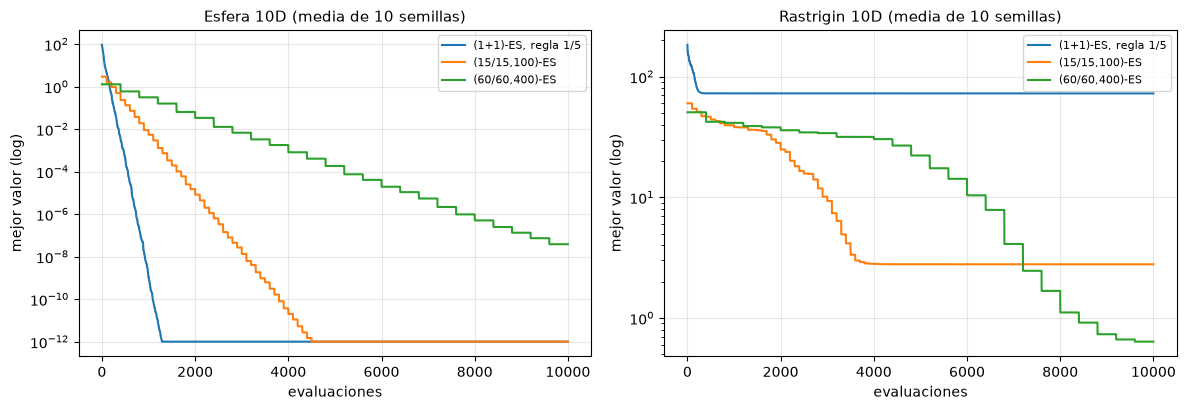

                              final (media)     desv.
Esfera    (1+1)-ES, regla 1/5     4.58e-109  9.8e-109
          (15/15,100)-ES           2.97e-28   2.3e-28
          (60/60,400)-ES           3.84e-08   1.9e-08
Rastrigin (1+1)-ES, regla 1/5          72.6      29.3
          (15/15,100)-ES               2.79      1.54
          (60/60,400)-ES              0.636     0.722


In [16]:
def sphere(x):    return float(np.sum(x ** 2))
def rastrigin(x): return float(10 * len(x) + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x)))

def es_1plus1(f, n, iters, rng, lo=-5.12, hi=5.12, sigma0=1.0):
    # (1+1)-ES con regla del 1/5 (ventana de 10 iteraciones, factor 0.85)
    x = rng.uniform(lo, hi, n); fx = f(x); sigma = sigma0; exitos = 0; hist = [fx]
    for t in range(1, iters + 1):
        y = x + sigma * rng.standard_normal(n); fy = f(y)
        if fy <= fx: x, fx = y, fy; exitos += 1
        if t % 10 == 0:
            sigma *= (1 / 0.85) if exitos / 10 > 0.2 else 0.85; exitos = 0
        hist.append(fx)
    return np.array(hist)

def es_mu_lambda(f, n, evals, rng, mu=15, lam=100, lo=-5.12, hi=5.12, sigma0=1.0):
    # (mu/mu, lambda)-ES con autoadaptación isotrópica de sigma y recombinación intermedia
    tau = 1 / np.sqrt(n)
    X = rng.uniform(lo, hi, (mu, n)); S = np.full(mu, sigma0); best = np.inf; hist = []
    ne = 0
    while ne < evals:
        xm, sm = X.mean(0), np.exp(np.log(S).mean())                  # recombinación (media geométrica para sigma)
        sig = sm * np.exp(tau * rng.standard_normal(lam))
        Y = xm + sig[:, None] * rng.standard_normal((lam, n))
        fy = np.array([f(y) for y in Y]); ne += lam
        o = np.argsort(fy)[:mu]; X, S = Y[o], sig[o]                  # selección coma
        best = min(best, fy[o[0]]); hist += [best] * lam
    return np.array(hist[:evals])

n = 10; EV = 10000
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2)); filas = {}
for ax, (nombre, f) in zip(axs, [("Esfera", sphere), ("Rastrigin", rastrigin)]):
    H1 = np.array([es_1plus1(f, n, EV, np.random.default_rng(s)) for s in range(10)])
    H2 = np.array([es_mu_lambda(f, n, EV, np.random.default_rng(s)) for s in range(10)])
    H3 = np.array([es_mu_lambda(f, n, EV, np.random.default_rng(s), mu=60, lam=400) for s in range(10)])
    for H, lab in [(H1[:, :EV], "(1+1)-ES, regla 1/5"), (H2, "(15/15,100)-ES"), (H3, "(60/60,400)-ES")]:
        ax.semilogy(np.arange(EV), np.maximum(H.mean(0), 1e-12), label=lab)
        filas[(nombre, lab)] = (H[:, -1].mean(), H[:, -1].std(ddof=1))
    ax.set_title(f"{nombre} 10D (media de 10 semillas)"); ax.set_xlabel("evaluaciones"); ax.set_ylabel("mejor valor (log)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(pd.DataFrame({k: {"final (media)": v[0], "desv.": v[1]} for k, v in filas.items()}).T.apply(lambda s: s.map("{:.3g}".format)))

**Lectura.** En la esfera (unimodal) las tres variantes convergen log-linealmente (rectas en escala logarítmica) gracias a la adaptación de $\sigma$; la $(1+1)$-ES es la más eficiente por evaluación y las poblaciones mayores son más lentas por evaluación (más evaluaciones por iteración). En Rastrigin (multimodal) ocurre lo contrario: la $(1+1)$-ES, elitista y de población única, se atasca en un mínimo local (valor final medio muy alto), mientras que las ES con selección coma y población mayor llegan mucho más cerca del óptimo global (0), y la mayor $(60/60,400)$ es la mejor de las tres en esta corrida (ver tabla). La recombinación intermedia promedia el paisaje local y la población grande explora más. Es el mismo compromiso exploración/explotación del AG, ahora controlado por el tamaño de paso y la población.

## Ventajas y limitaciones

| Aspecto | Ventajas | Limitaciones |
|---|---|---|
| Búsqueda poblacional | explora varias regiones a la vez; paralelizable; robusta a ruido | costo en evaluaciones por la población; puede converger prematuramente |
| Cruce | combina estructura de padres; permite saltos grandes | requiere operadores específicos (permutaciones); inútil si destruye lo que importa |
| Generalidad | solo necesita una función de aptitud y una representación | sin garantías prácticas de optimalidad; muchos parámetros (μ, pc, pm, presión) |
| Teoría | modelos cualitativos (esquemas, toma de control) | el teorema de esquemas no predice dinámica ni convergencia |
| Rendimiento | buen comportamiento global en paisajes multimodales | un AG "puro" suele perder ante búsqueda local en TSP/QAP pequeños; mejora con hibridación |

## Resumen
- Un AG = población + selección + variación + reemplazo; cada pieza controla exploración/explotación.
- La **presión selectiva** se puede medir (copias esperadas, tiempo de toma de control); la ruleta sobre $1/f$ casi no tiene presión.
- En permutaciones, el cruce debe **heredar lo que el problema valora**: aristas en TSP (ER, OX), posiciones en QAP (PMX, CX). Validamos que todos los operadores producen permutaciones válidas.
- El **elitismo** y los esquemas $(\mu+\lambda)$ aceleran la convergencia a costa de diversidad; $(\mu,\lambda)$ es la base de las ES.
- El **teorema de esquemas** es una cota de un paso; no justifica por sí solo la eficacia del AG.
- Las ES resuelven el caso continuo con autoadaptación del tamaño de paso.

## Ejercicios propuestos
1. Implementa selección por **ranking exponencial** y compara su tiempo de toma de control con el ranking lineal.
2. Añade el cruce **de aristas con prioridad a las comunes** (*EAX* simplificado) y mide cuántas aristas hereda en el TSP.
3. Haz un **barrido** de $p_m\in\{0.05,0.1,0.2,0.4,0.8\}$ y de $\mu\in\{20,40,80,160\}$ con el presupuesto fijo; ¿existe interacción entre ambos?
4. Introduce **control de diversidad**: reemplaza individuos con distancia de Hamming $<\theta$ de otro mejor (*crowding determinista*) y compara la diversidad final.
5. Extiende el experimento de esquemas a un problema con **engaño** (trampa de orden 4) y observa cómo el AG simple falla aunque la cota se cumpla.
6. Aplica el AG a una instancia de QAP de tamaño 30 y compara con búsqueda tabú ([notebook 06](../02-metodos-con-memoria/06-busqueda-tabu.ipynb)) con igual presupuesto.

## Referencias
- Holland, J. H. (1975). *Adaptation in Natural and Artificial Systems*. University of Michigan Press.
- Goldberg, D. E. (1989). *Genetic Algorithms in Search, Optimization and Machine Learning*. Addison-Wesley.
- Eiben, A. E., Smith, J. E. (2003). *Introduction to Evolutionary Computing*. Springer.
- Goldberg, D. E., Lingle, R. (1985). Alleles, loci and the traveling salesman problem. *Proc. ICGA*.
- Davis, L. (1985). Applying adaptive algorithms to epistatic domains. *Proc. IJCAI*.
- Whitley, D., Starkweather, T., Fuquay, D. (1989). Scheduling problems and traveling salesmen: the genetic edge recombination operator. *Proc. ICGA*.
- Oliver, I. M., Smith, D. J., Holland, J. R. C. (1987). A study of permutation crossover operators on the traveling salesman problem. *Proc. ICGA*.
- Syswerda, G. (1989). Uniform crossover in genetic algorithms. *Proc. ICGA*.
- Blickle, T., Thiele, L. (1996). A comparison of selection schemes used in evolutionary algorithms. *Evolutionary Computation*, 4(4).
- Goldberg, D. E., Deb, K. (1991). A comparative analysis of selection schemes used in genetic algorithms. *Foundations of Genetic Algorithms*.
- Vose, M. D. (1999). *The Simple Genetic Algorithm: Foundations and Theory*. MIT Press.
- Beyer, H.-G., Schwefel, H.-P. (2002). Evolution strategies: a comprehensive introduction. *Natural Computing*, 1.
- Rechenberg, I. (1973). *Evolutionsstrategie*. Frommann-Holzboog.